# Agent Eval Analysis

Analysis of historical agent evaluation reports.

Goals:
- track Outcome, Capability, and Grounding pass rates across runs;
- identify unstable or consistently failing eval cases;
- inspect missing evaluation data;
- prepare data for trend visualization.

## Setup

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.ticker import PercentFormatter

from prokat24_ai_lab.evals.semantic_grading import (
    build_grader_confusion_matrix,
    calculate_grader_classification_metrics,
    summarize_grader_comparison,
    summarize_grader_stability,
)

PROJECT_ROOT = Path.cwd().parent
RUNS_DIR = PROJECT_ROOT / "reports" / "agent" / "runs"

assert RUNS_DIR.exists(), f"Reports directory not found: {RUNS_DIR}"

GRADER_REPORT_FILE = PROJECT_ROOT / "reports" / "grader" / "holdout" / "latest.json"

assert GRADER_REPORT_FILE.exists(), f"Grader report not found: {GRADER_REPORT_FILE}"

In [2]:
report_files = sorted(RUNS_DIR.glob("*.json"))

assert report_files, "No historical agent eval reports found"

print(f"Reports found: {len(report_files)}")

Reports found: 4


## Load and prepare historical results

Load all historical agent eval reports and convert case-level results into a single flat DataFrame.

In [3]:
# Load historical agent eval reports
run_frames = []

for report_file in report_files:
    with open(report_file, encoding="utf-8") as file:
        run_report = json.load(file)

    run_df = pd.json_normalize(run_report["results"])

    run_df = run_df[
        [
            "id",
            "outcome.passed",
            "capability.passed",
            "grounding.passed",
        ]
    ].rename(
        columns={
            "outcome.passed": "outcome",
            "capability.passed": "capability",
            "grounding.passed": "grounding",
        }
    )

    run_df["run_id"] = run_report["run_id"]
    run_df["created_at"] = run_report["created_at"]

    run_frames.append(run_df)

history_df = pd.concat(run_frames, ignore_index=True)
history_df = history_df[
    [
        "id",
        "run_id",
        "created_at",
        "outcome",
        "capability",
        "grounding",
    ]
]
history_df["created_at"] = pd.to_datetime(
    history_df["created_at"],
    utc=True,
)

In [4]:
# Prepare agent eval history dataframe
history_df.head()

,id,run_id,created_at,outcome,capability,grounding
0,tent_price_3_days,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,True
1,tent_search,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,False
2,tent_deposit,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,False
3,kyiv_delivery,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,True
4,booking_rules,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,True,True,True


## Data quality

Check evaluation coverage and missing values before calculating aggregate metrics.

In [5]:
# Calculate data quality metrics
metrics = ["outcome", "capability", "grounding"]
data_quality = pd.DataFrame(
    {
        "evaluated": history_df[metrics].count(),
        "missing": history_df[metrics].isna().sum(),
        "coverage": history_df[metrics].notna().mean(),
    }
).reset_index(names="metric")

data_quality.insert(1, "total", len(history_df))

data_quality

,metric,total,evaluated,missing,coverage
0,outcome,40,40,0,1.0
1,capability,40,40,0,1.0
2,grounding,40,40,0,1.0


## Run-level metrics

Calculate Outcome, Capability, and Grounding pass rates for each historical eval run.

In [6]:
# Calculate run-level pass rates
run_stats = (
    history_df.groupby(["run_id", "created_at"])[["outcome", "capability", "grounding"]]
    .mean()
    .reset_index()
    .sort_values("created_at")
)

run_stats

,run_id,created_at,outcome,capability,grounding
0,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,0.9,1.0,0.8
1,20260925T203657Z_4aade3a,2026-09-25 20:36:57+00:00,0.8,1.0,0.6
2,20260929T190809Z_0d25463,2026-09-29 19:08:09+00:00,0.9,0.9,0.8
3,20261022T194819Z_1a3d34a,2026-10-22 19:48:19+00:00,0.9,0.9,0.9


## Case-level diagnostics

Combine historical pass rates and stability indicators for each eval case.

In [7]:
# Calculate case-level pass rates
case_pass_rates = (
    history_df.groupby("id")
    .agg(
        runs=("run_id", "nunique"),
        outcome=("outcome", "mean"),
        capability=("capability", "mean"),
        grounding=("grounding", "mean"),
    )
    .reset_index()
)

In [8]:
# Calculate case-level stability
case_stability = (
    history_df.groupby("id")[["outcome", "capability", "grounding"]].nunique().reset_index()
)

In [9]:
# Build combined case diagnostics
state_columns = [f"{metric}_states" for metric in metrics]
stability_columns = [f"{metric}_stability" for metric in metrics]

stability_for_merge = case_stability.rename(
    columns={metric: f"{metric}_states" for metric in metrics}
)

case_diagnostics = case_pass_rates.merge(
    stability_for_merge,
    on="id",
)

for metric in metrics:
    case_diagnostics[f"{metric}_stability"] = case_diagnostics[f"{metric}_states"].map(
        {1: "stable", 2: "unstable"}
    )

case_diagnostics = case_diagnostics.drop(columns=state_columns)

case_diagnostics["unstable_metrics"] = (
    case_diagnostics[stability_columns].eq("unstable").sum(axis=1)
)

case_diagnostics["worst_pass_rate"] = case_diagnostics[metrics].min(axis=1)

case_diagnostics = case_diagnostics.sort_values(
    ["unstable_metrics", "worst_pass_rate"],
    ascending=[False, True],
).reset_index(drop=True)

case_diagnostics

,id,runs,outcome,capability,grounding,outcome_stability,capability_stability,grounding_stability,unstable_metrics,worst_pass_rate
0,equipment_purchase,4,0.75,0.5,0.75,unstable,unstable,unstable,3,0.50
1,equipment_cleaning,4,0.00,1.0,0.75,stable,stable,unstable,1,0.00
2,tent_search,4,1.00,1.0,0.50,stable,stable,unstable,1,0.50
3,pickup_locations,4,1.00,1.0,0.75,stable,stable,unstable,1,0.75
4,tent_deposit,4,1.00,1.0,0.00,stable,stable,stable,0,0.00
5,booking_contact,4,1.00,1.0,1.00,stable,stable,stable,0,1.00
6,booking_rules,4,1.00,1.0,1.00,stable,stable,stable,0,1.00
7,kyiv_delivery,4,1.00,1.0,1.00,stable,stable,stable,0,1.00
8,outside_kyiv_delivery,4,1.00,1.0,1.00,stable,stable,stable,0,1.00
9,tent_price_3_days,4,1.00,1.0,1.00,stable,stable,stable,0,1.00


## Run-level trends

Visualize Outcome, Capability, and Grounding pass rates across historical eval runs.

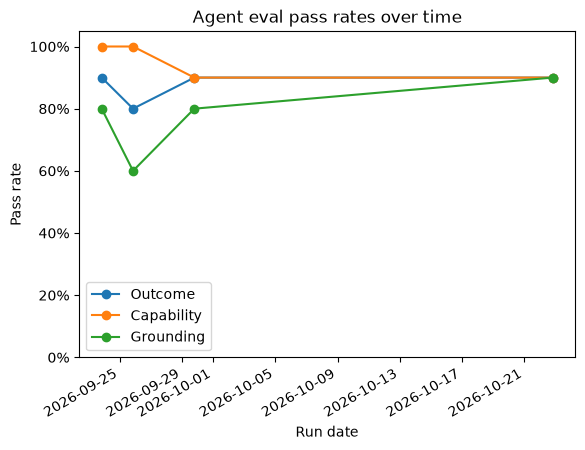

In [10]:
# Plot agent eval trends
fig, ax = plt.subplots()

for metric in metrics:
    ax.plot(
        run_stats["created_at"],
        run_stats[metric],
        marker="o",
        label=metric.capitalize(),
    )

ax.set_title("Agent eval pass rates over time")
ax.set_xlabel("Run date")
ax.set_ylabel("Pass rate")
ax.set_ylim(0, 1.05)
ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.legend()

fig.autofmt_xdate()

plt.show()

## Case-level triage

Visualize the weakest historical pass rate for each eval case.

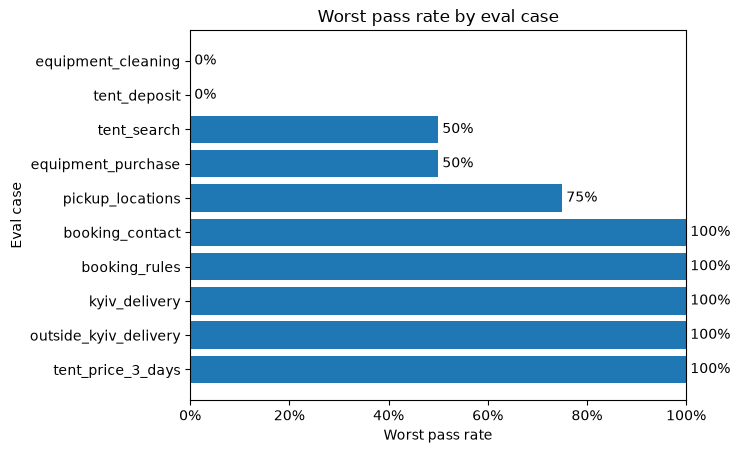

In [11]:
# Build case-level triage chart
triage_df = case_diagnostics.sort_values("worst_pass_rate").reset_index(drop=True)

fig, ax = plt.subplots()

bars = ax.barh(
    triage_df["id"],
    triage_df["worst_pass_rate"],
)
ax.bar_label(
    bars,
    labels=[f"{value:.0%}" for value in triage_df["worst_pass_rate"]],
    padding=3,
)

ax.set_title("Worst pass rate by eval case")
ax.set_xlabel("Worst pass rate")
ax.set_ylabel("Eval case")
ax.set_xlim(0, 1)

ax.xaxis.set_major_formatter(PercentFormatter(1.0))

ax.invert_yaxis()

plt.show()

## Statistical reliability

Calculate pass rates, confidence intervals, and paired run comparisons for historical eval results.

### Statistical helper functions

Helper functions for Wilson confidence intervals and the exact McNemar test.

In [12]:
# Statistical helper functions
def wilson_interval(
    passed: int,
    total: int,
) -> tuple[float, float]:
    from math import sqrt

    z = 1.96
    n = total

    p = passed / n
    denominator = 1 + z**2 / n

    center = (p + z**2 / (2 * n)) / denominator

    margin = z * sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denominator

    lower = center - margin
    upper = center + margin

    return lower, upper


def exact_mcnemar_p_value(
    improved: int,
    worsened: int,
) -> float:
    from math import comb

    discordant = improved + worsened

    if discordant == 0:
        return 1.0

    smaller = min(improved, worsened)

    one_side_probability = sum(comb(discordant, k) * 0.5**discordant for k in range(smaller + 1))

    return min(1.0, 2 * one_side_probability)


def cohens_kappa(
    tp: int,
    tn: int,
    fp: int,
    fn: int,
) -> float:
    total = tp + tn + fp + fn

    if total == 0:
        return 0.0

    observed_agreement = (tp + tn) / total

    human_pass = tp + fn
    human_fail = tn + fp

    judge_pass = tp + fp
    judge_fail = tn + fn

    expected_agreement = (human_pass / total) * (judge_pass / total) + (human_fail / total) * (
        judge_fail / total
    )

    if expected_agreement == 1.0:
        return 1.0

    return (observed_agreement - expected_agreement) / (1 - expected_agreement)

### Confidence intervals

Calculate pass rates and 95% Wilson confidence intervals for each eval metric and historical run.

In [13]:
# Calculate Wilson confidence intervals
reliability_df = history_df.melt(
    id_vars=["id", "run_id", "created_at"],
    value_vars=metrics,
    var_name="metric",
    value_name="passed",
)

reliability_summary = (
    reliability_df.groupby(["run_id", "created_at", "metric"])
    .agg(
        passed=("passed", "sum"),
        total=("passed", "count"),
        pass_rate=("passed", "mean"),
    )
    .reset_index()
)

reliability_summary[["ci_lower", "ci_upper"]] = reliability_summary.apply(
    lambda row: pd.Series(
        wilson_interval(
            int(row["passed"]),
            int(row["total"]),
        )
    ),
    axis=1,
)

reliability_display = reliability_summary.copy()

reliability_display["pass_rate"] = reliability_display["pass_rate"].map(
    lambda value: f"{value:.0%}"
)

reliability_display["wilson_95_ci"] = reliability_display.apply(
    lambda row: f"{row['ci_lower']:.2%} - {row['ci_upper']:.2%}",
    axis=1,
)

reliability_display = reliability_display.drop(columns=["ci_lower", "ci_upper"])

reliability_display

,run_id,created_at,metric,passed,total,pass_rate,wilson_95_ci
0,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,capability,10,10,100%,72.25% - 100.00%
1,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,grounding,8,10,80%,49.02% - 94.33%
2,20260923T201818Z_1a59d48,2026-09-23 20:18:18+00:00,outcome,9,10,90%,59.58% - 98.21%
3,20260925T203657Z_4aade3a,2026-09-25 20:36:57+00:00,capability,10,10,100%,72.25% - 100.00%
4,20260925T203657Z_4aade3a,2026-09-25 20:36:57+00:00,grounding,6,10,60%,31.27% - 83.18%
5,20260925T203657Z_4aade3a,2026-09-25 20:36:57+00:00,outcome,8,10,80%,49.02% - 94.33%
6,20260929T190809Z_0d25463,2026-09-29 19:08:09+00:00,capability,9,10,90%,59.58% - 98.21%
7,20260929T190809Z_0d25463,2026-09-29 19:08:09+00:00,grounding,8,10,80%,49.02% - 94.33%
8,20260929T190809Z_0d25463,2026-09-29 19:08:09+00:00,outcome,9,10,90%,59.58% - 98.21%
9,20261022T194819Z_1a3d34a,2026-10-22 19:48:19+00:00,capability,9,10,90%,59.58% - 98.21%


### Paired run comparison

Compare the two latest runs case by case.  
McNemar's test evaluates whether PASS/FAIL changes are systematically biased toward improvement or worsening.

**Transition matrix — previous run → current run**

In [14]:
# Compare the two latest agent eval runs
latest_run_ids = (
    history_df[["run_id", "created_at"]]
    .drop_duplicates()
    .sort_values("created_at")["run_id"]
    .tail(2)
    .tolist()
)

previous_run_id, current_run_id = latest_run_ids

comparison_rows = []
transition_tables = []

for metric in metrics:
    previous_values = history_df.loc[
        history_df["run_id"] == previous_run_id,
        ["id", metric],
    ].rename(columns={metric: "previous"})

    current_values = history_df.loc[
        history_df["run_id"] == current_run_id,
        ["id", metric],
    ].rename(columns={metric: "current"})

    paired = previous_values.merge(
        current_values,
        on="id",
    )

    improved = int(((~paired["previous"]) & paired["current"]).sum())

    worsened = int((paired["previous"] & (~paired["current"])).sum())

    unchanged = int((paired["previous"] == paired["current"]).sum())

    p_value = exact_mcnemar_p_value(
        improved=improved,
        worsened=worsened,
    )

    previous_pass_rate = paired["previous"].mean()
    current_pass_rate = paired["current"].mean()

    comparison_rows.append(
        {
            "metric": metric,
            "previous_pass_rate": previous_pass_rate,
            "current_pass_rate": current_pass_rate,
            "delta": current_pass_rate - previous_pass_rate,
            "improved": improved,
            "worsened": worsened,
            "unchanged": unchanged,
            "mcnemar_p_value": p_value,
        }
    )

    transition_table = (
        pd.crosstab(
            paired["previous"],
            paired["current"],
        )
        .reindex(
            index=[False, True],
            columns=[False, True],
            fill_value=0,
        )
        .rename(
            index={False: "FAIL", True: "PASS"},
            columns={False: "FAIL", True: "PASS"},
        )
        .reset_index()
    )
    transition_table.columns.name = None

    transition_table.insert(0, "metric", metric)

    transition_tables.append(transition_table)

transition_summary = pd.concat(
    transition_tables,
    ignore_index=True,
)

comparison_summary = pd.DataFrame(comparison_rows)

transition_summary

,metric,previous,FAIL,PASS
0,outcome,FAIL,1,0
1,outcome,PASS,0,9
2,capability,FAIL,1,0
3,capability,PASS,0,9
4,grounding,FAIL,1,1
5,grounding,PASS,0,8


In [15]:
# Calculate paired run comparison metrics
comparison_display = comparison_summary.copy()

for column in [
    "previous_pass_rate",
    "current_pass_rate",
]:
    comparison_display[column] = comparison_display[column].map(lambda value: f"{value:.0%}")

comparison_display["delta"] = comparison_display["delta"].map(lambda value: f"{value:+.0%}")

comparison_display

,metric,previous_pass_rate,current_pass_rate,delta,improved,worsened,unchanged,mcnemar_p_value
0,outcome,90%,90%,+0%,0,0,10,1.0
1,capability,90%,90%,+0%,0,0,10,1.0
2,grounding,80%,90%,+10%,1,0,9,1.0


### Judge reliability

Analyze LLM judge agreement with human-labeled holdout cases using real grader comparison results.

In [16]:
# Load grader comparison report
with open(GRADER_REPORT_FILE, encoding="utf-8") as file:
    grader_report = json.load(file)

grader_runs = grader_report["runs"]

In [17]:
# Calculate judge reliability metrics
judge_rows = []

grader_configs = [
    (
        "Holistic LLM",
        "llm_passed",
        "llm_accuracy",
    ),
    (
        "Criterion LLM",
        "criterion_llm_passed",
        "criterion_llm_accuracy",
    ),
]

for run_number, results in enumerate(grader_runs, start=1):
    summary = summarize_grader_comparison(results)

    for grader_name, grader_key, accuracy_key in grader_configs:
        matrix = build_grader_confusion_matrix(
            results,
            grader_key,
        )

        kappa = cohens_kappa(
            tp=matrix["true_positive"],
            tn=matrix["true_negative"],
            fp=matrix["false_positive"],
            fn=matrix["false_negative"],
        )

        classification = calculate_grader_classification_metrics(matrix)

        judge_rows.append(
            {
                "run": run_number,
                "judge": grader_name,
                "TP": matrix["true_positive"],
                "TN": matrix["true_negative"],
                "FP": matrix["false_positive"],
                "FN": matrix["false_negative"],
                "accuracy": summary[accuracy_key],
                "precision": classification["precision"],
                "recall": classification["recall"],
                "kappa": kappa,
            }
        )

judge_reliability_df = pd.DataFrame(judge_rows)

In [18]:
# Format judge reliability results
judge_reliability_display = judge_reliability_df.copy()

for column in [
    "accuracy",
    "precision",
    "recall",
]:
    judge_reliability_display[column] = judge_reliability_display[column].map(
        lambda value: f"{value:.2%}"
    )

judge_reliability_display["kappa"] = judge_reliability_display["kappa"].map(
    lambda value: f"{value:.2f}"
)

judge_reliability_display

,run,judge,TP,TN,FP,FN,accuracy,precision,recall,kappa
0,1,Holistic LLM,5,7,0,0,100.00%,100.00%,100.00%,1.00
1,1,Criterion LLM,5,7,0,0,100.00%,100.00%,100.00%,1.00
2,2,Holistic LLM,5,6,1,0,91.67%,83.33%,100.00%,0.83
3,2,Criterion LLM,5,7,0,0,100.00%,100.00%,100.00%,1.00
4,3,Holistic LLM,5,7,0,0,100.00%,100.00%,100.00%,1.00
5,3,Criterion LLM,5,7,0,0,100.00%,100.00%,100.00%,1.00


In [19]:
# Calculate judge stability across repeated runs
judge_stability = summarize_grader_stability(grader_runs)

judge_stability_df = pd.DataFrame(
    [
        {
            "id": result["id"],
            "expected": "PASS" if result["expected_passed"] else "FAIL",
            "holistic_stable": result["llm_stable"],
            "holistic_match_rate": result["llm_match_rate"],
            "criterion_stable": result["criterion_llm_stable"],
            "criterion_match_rate": result["criterion_llm_match_rate"],
        }
        for result in judge_stability
    ]
)

In [20]:
# Format unstable judge cases
judge_stability_display = judge_stability_df.loc[
    (~judge_stability_df["holistic_stable"])
    | (~judge_stability_df["criterion_stable"])
    | (judge_stability_df["holistic_match_rate"] < 1.0)
    | (judge_stability_df["criterion_match_rate"] < 1.0)
].copy()

for column in [
    "holistic_match_rate",
    "criterion_match_rate",
]:
    judge_stability_display[column] = judge_stability_display[column].map(
        lambda value: f"{value:.2%}"
    )

judge_stability_display

,id,expected,holistic_stable,holistic_match_rate,criterion_stable,criterion_match_rate
10,address_irrelevant_extra_01,FAIL,False,66.67%,True,100.00%


## Conclusions

In [21]:
# Build dynamic conclusions
latest_run = run_stats.iloc[-1]

unstable_case_ids = case_diagnostics.loc[
    case_diagnostics["unstable_metrics"] > 0,
    "id",
].tolist()

consistently_failing_cases = {}

for metric in metrics:
    consistently_failing_cases[metric] = case_diagnostics.loc[
        (case_diagnostics[metric] == 0) & (case_diagnostics[f"{metric}_stability"] == "stable"),
        "id",
    ].tolist()

judge_case_count = len(grader_runs[0])

print(f"Historical runs analyzed: {len(run_stats)}")
print(f"Latest Outcome pass rate: {latest_run['outcome']:.0%}")
print(f"Latest Capability pass rate: {latest_run['capability']:.0%}")
print(f"Latest Grounding pass rate: {latest_run['grounding']:.0%}")
print("Unstable cases: " + (", ".join(unstable_case_ids) if unstable_case_ids else "none"))

for metric, case_ids in consistently_failing_cases.items():
    print(
        f"Consistently failing {metric.capitalize()} cases: "
        + (", ".join(case_ids) if case_ids else "none")
    )

print()
print(f"Judge holdout cases analyzed: {judge_case_count}")

for judge_name in [
    "Holistic LLM",
    "Criterion LLM",
]:
    judge_rows = judge_reliability_df.loc[judge_reliability_df["judge"] == judge_name]

    min_accuracy = judge_rows["accuracy"].min()
    max_accuracy = judge_rows["accuracy"].max()

    stable_column = "holistic_stable" if judge_name == "Holistic LLM" else "criterion_stable"

    unstable_judge_cases = judge_stability_df.loc[
        ~judge_stability_df[stable_column],
        "id",
    ].tolist()

    print(f"{judge_name} accuracy range: {min_accuracy:.2%} - {max_accuracy:.2%}")

    print(
        f"{judge_name} unstable cases: "
        + (", ".join(unstable_judge_cases) if unstable_judge_cases else "none")
    )

Historical runs analyzed: 4
Latest Outcome pass rate: 90%
Latest Capability pass rate: 90%
Latest Grounding pass rate: 90%
Unstable cases: equipment_purchase, equipment_cleaning, tent_search, pickup_locations
Consistently failing Outcome cases: equipment_cleaning
Consistently failing Capability cases: none
Consistently failing Grounding cases: tent_deposit

Judge holdout cases analyzed: 12
Holistic LLM accuracy range: 91.67% - 100.00%
Holistic LLM unstable cases: address_irrelevant_extra_01
Criterion LLM accuracy range: 100.00% - 100.00%
Criterion LLM unstable cases: none
